In [16]:
from pathlib import Path
import time
import json
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras

np.set_printoptions(precision=3, suppress=True)

SEED = 2026
BATCH_SIZE = 128
EPOCHS = 50
results_dir = Path("wyniki_zapalenie_pluc")
results_dir.mkdir(exist_ok=True)

In [17]:
data = np.load("pneumoniamnist_64.npz")

X_data = data["train_images"].reshape(-1, 64, 64, 1)
y_data = data["train_labels"].ravel()
X_val = data["val_images"].reshape(-1, 64, 64, 1)
y_val = data["val_labels"].ravel()
X_test = data["test_images"].reshape(-1, 64, 64, 1)
y_test = data["test_labels"].ravel()

class_names = ["zdrowy", "zapalenie"]

print("Trening:", X_data.shape, "Walidacja:", X_val.shape, "Test:", X_test.shape)
print("Zakres pikseli:", X_data.min(), "-", X_data.max())
print("Liczebności klas w treningu:", np.bincount(y_data))
print("Liczebności klas w walidacji:", np.bincount(y_val))
print("Liczebności klas w teście:", np.bincount(y_test))

Trening: (4708, 64, 64, 1) Walidacja: (524, 64, 64, 1) Test: (624, 64, 64, 1)
Zakres pikseli: 0 - 255
Liczebności klas w treningu: [1214 3494]
Liczebności klas w walidacji: [135 389]
Liczebności klas w teście: [234 390]


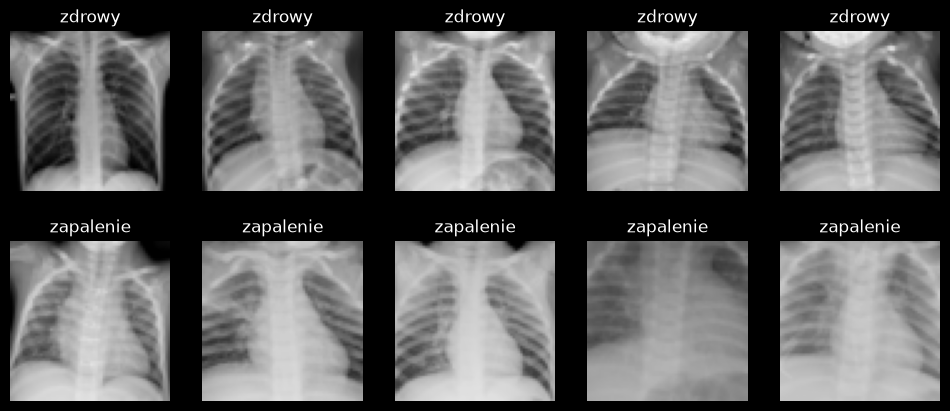

In [18]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for row, label in enumerate([0, 1]):
    indices = np.flatnonzero(y_data == label)[:5]
    for ax, index in zip(axes[row], indices):
        ax.imshow(X_data[index, :, :, 0], cmap="gray", vmin=0, vmax=255)
        ax.set_title(class_names[label])
        ax.axis("off")
fig.savefig(results_dir / "przyklady_rtg.png", dpi=150, bbox_inches="tight")
plt.show()

In [19]:
train_sets = {}
for percent in [10, 30, 100]:
    indices = []
    for label in range(2):
        label_indices = np.flatnonzero(y_data == label)
        n = len(label_indices) * percent // 100
        indices.extend(label_indices[:n])
    train_sets[percent] = (X_data[indices], y_data[indices])
    print(f"{percent}%:", len(indices), "zdjęć, zdrowi / zapalenie:", np.bincount(y_data[indices]))

10%: 470 zdjęć, zdrowi / zapalenie: [121 349]
30%: 1412 zdjęć, zdrowi / zapalenie: [ 364 1048]
100%: 4708 zdjęć, zdrowi / zapalenie: [1214 3494]


In [20]:
def confusion_matrix_binary(y_true, y_pred):
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    return {"TP": tp, "TN": tn, "FP": fp, "FN": fn}


def safe_divide(numerator, denominator):
    if denominator == 0:
        return 0.0
    return float(numerator / denominator)


def classification_metrics_binary(y_true, y_pred):
    counts = confusion_matrix_binary(y_true, y_pred)
    tp = counts["TP"]
    tn = counts["TN"]
    fp = counts["FP"]
    fn = counts["FN"]

    counts["accuracy"] = safe_divide(tp + tn, tp + tn + fp + fn)
    counts["recall"] = safe_divide(tp, tp + fn)
    counts["precision"] = safe_divide(tp, tp + fp)
    counts["f1"] = safe_divide(2 * tp, 2 * tp + fp + fn)
    return counts


def show_scores(name, metrics):
    print(name)
    print("  Dokładność:", round(metrics["accuracy"], 3))
    print("  Czułość:", round(metrics["recall"], 3))
    print("  Precyzja:", round(metrics["precision"], 3))
    print("  F1:", round(metrics["f1"], 3))


def plot_confusion_matrix(counts, title):
    matrix = np.array([
        [counts["TN"], counts["FP"]],
        [counts["FN"], counts["TP"]]
    ])

    plt.imshow(matrix, cmap="Blues", vmin=0, vmax=matrix.sum())
    plt.text(0, 0, f"TN\n{counts['TN']}", ha="center", va="center", color="red")
    plt.text(1, 0, f"FP\n{counts['FP']}", ha="center", va="center", color="red")
    plt.text(0, 1, f"FN\n{counts['FN']}", ha="center", va="center", color="red")
    plt.text(1, 1, f"TP\n{counts['TP']}", ha="center", va="center", color="red")
    plt.xticks([0, 1], ["Zdrowi (0)", "Chorzy (1)"])
    plt.yticks([0, 1], ["Zdrowi (0)", "Chorzy (1)"])
    plt.xlabel("Przewidywana klasa")
    plt.ylabel("Rzeczywista klasa")
    plt.title(title)
    plt.show()

Klasa większościowa: 1 - zapalenie
Model bazowy: zawsze zapalenie
  Dokładność: 0.742
  Czułość: 1.0
  Precyzja: 0.742
  F1: 0.852


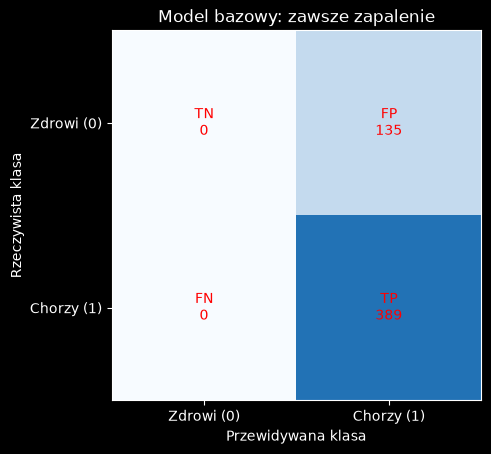

In [21]:
majority_class = np.bincount(y_data).argmax()
val_baseline_pred = np.full(len(y_val), majority_class)
val_baseline_metrics = classification_metrics_binary(y_val, val_baseline_pred)

print("Klasa większościowa:", majority_class, "-", class_names[majority_class])
show_scores("Model bazowy: zawsze zapalenie", val_baseline_metrics)
plot_confusion_matrix(val_baseline_metrics, "Model bazowy: zawsze zapalenie")

In [22]:
def make_callbacks(output_dir):
    stop = keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=8, min_delta=0.001, restore_best_weights=True,
    )
    reduce = keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=3, min_delta=0.001, min_lr=0.00001,
    )
    logger = keras.callbacks.CSVLogger(str(output_dir / "historia.csv"))
    return [stop, reduce, logger]


def count_trainable(model):
    return int(sum(np.prod(w.shape) for w in model.trainable_weights))


def plot_history(history, output_dir, title):
    epochs = np.arange(1, len(history.history["loss"]) + 1)
    best_epoch = int(np.argmin(history.history["val_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
    for ax, key, label in zip(axes, ["loss", "accuracy"], ["BCE", "Dokładność"]):
        ax.plot(epochs, history.history[key], label="Trening")
        ax.plot(epochs, history.history[f"val_{key}"], label="Walidacja")
        ax.axvline(best_epoch, color="gray", linestyle=":", label="Wybrana epoka")
        ax.set(xlabel="Epoka", ylabel=label, title=f"{title}: {label}")
        ax.grid(alpha=0.2)
        ax.legend()
    axes[0].set_ylim(bottom=0)
    axes[1].set_ylim(0, 1)
    fig.savefig(output_dir / "historia.png", dpi=150, bbox_inches="tight")
    plt.show()
    return best_epoch


def inference_time_ms(model, X):
    model.predict(X[:BATCH_SIZE], verbose=0)
    start = time.perf_counter()
    model.predict(X, batch_size=BATCH_SIZE, verbose=0)
    elapsed = time.perf_counter() - start
    return 1000 * elapsed / len(X)

In [53]:
PERCENT = 100
RUN_NAME = f"cnn_{PERCENT}"
output_dir = results_dir / RUN_NAME
output_dir.mkdir(parents=True, exist_ok=True)
X_train, y_train = train_sets[PERCENT]

keras.backend.clear_session()
keras.utils.set_random_seed(SEED)

cnn = keras.Sequential([
    keras.layers.Input(shape=(64, 64, 1)),
    keras.layers.Rescaling(1 / 255.0),

    keras.layers.Conv2D(32, 3, padding="same", use_bias=False, kernel_initializer="he_normal"),
    keras.layers.BatchNormalization(momentum=0.9),
    keras.layers.ReLU(),
    keras.layers.Conv2D(32, 3, padding="same", use_bias=False, kernel_initializer="he_normal"),
    keras.layers.BatchNormalization(momentum=0.9),
    keras.layers.ReLU(),
    keras.layers.MaxPooling2D(2),
    keras.layers.Dropout(0.1),

    keras.layers.Conv2D(64, 3, padding="same", use_bias=False, kernel_initializer="he_normal"),
    keras.layers.BatchNormalization(momentum=0.9),
    keras.layers.ReLU(),
    keras.layers.Conv2D(64, 3, padding="same", use_bias=False, kernel_initializer="he_normal"),
    keras.layers.BatchNormalization(momentum=0.9),
    keras.layers.ReLU(),
    keras.layers.MaxPooling2D(2),
    keras.layers.Dropout(0.2),

    keras.layers.Conv2D(128, 3, padding="same", use_bias=False, kernel_initializer="he_normal"),
    keras.layers.BatchNormalization(momentum=0.9),
    keras.layers.ReLU(),
    keras.layers.Conv2D(128, 3, padding="same", use_bias=False, kernel_initializer="he_normal"),
    keras.layers.BatchNormalization(momentum=0.9),
    keras.layers.ReLU(),
    keras.layers.MaxPooling2D(2),
    keras.layers.Dropout(0.3),

    keras.layers.GlobalAveragePooling2D(),
    keras.layers.Dense(1, activation="sigmoid"),
])
print("Wszystkie parametry:", cnn.count_params())
print("Trenowane parametry:", count_trainable(cnn))
cnn.summary()

Wszystkie parametry: 287905
Trenowane parametry: 287009


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 287,905 (1.10 MB)

 Trainable params: 287,009 (1.09 MB)

 Non-trainable params: 896 (3.50 KB)

In [54]:
cnn.compile(
    optimizer=keras.optimizers.AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss=keras.losses.BinaryCrossentropy(),
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.Recall(name="recall"),
    ],
)

start = time.perf_counter()
history = cnn.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    callbacks=make_callbacks(output_dir),
    verbose=2,
)
train_time = time.perf_counter() - start
print("Czas treningu [s]:", round(train_time, 1))

Epoch 1/50
37/37 - 23s - 620ms/step - accuracy: 0.8766 - loss: 0.2958 - recall: 0.8898 - val_accuracy: 0.8073 - val_loss: 0.3937 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 2/50
37/37 - 22s - 589ms/step - accuracy: 0.9380 - loss: 0.1599 - recall: 0.9599 - val_accuracy: 0.9103 - val_loss: 0.2054 - val_recall: 0.9923 - learning_rate: 0.0010
Epoch 3/50
37/37 - 21s - 561ms/step - accuracy: 0.9471 - loss: 0.1351 - recall: 0.9671 - val_accuracy: 0.9523 - val_loss: 0.1291 - val_recall: 0.9871 - learning_rate: 0.0010
Epoch 4/50
37/37 - 21s - 559ms/step - accuracy: 0.9548 - loss: 0.1138 - recall: 0.9722 - val_accuracy: 0.9580 - val_loss: 0.1107 - val_recall: 0.9717 - learning_rate: 0.0010
Epoch 5/50
37/37 - 21s - 568ms/step - accuracy: 0.9652 - loss: 0.0951 - recall: 0.9785 - val_accuracy: 0.9561 - val_loss: 0.1079 - val_recall: 0.9820 - learning_rate: 0.0010
Epoch 6/50
37/37 - 21s - 568ms/step - accuracy: 0.9652 - loss: 0.0915 - recall: 0.9785 - val_accuracy: 0.9580 - val_loss: 0.0982 -

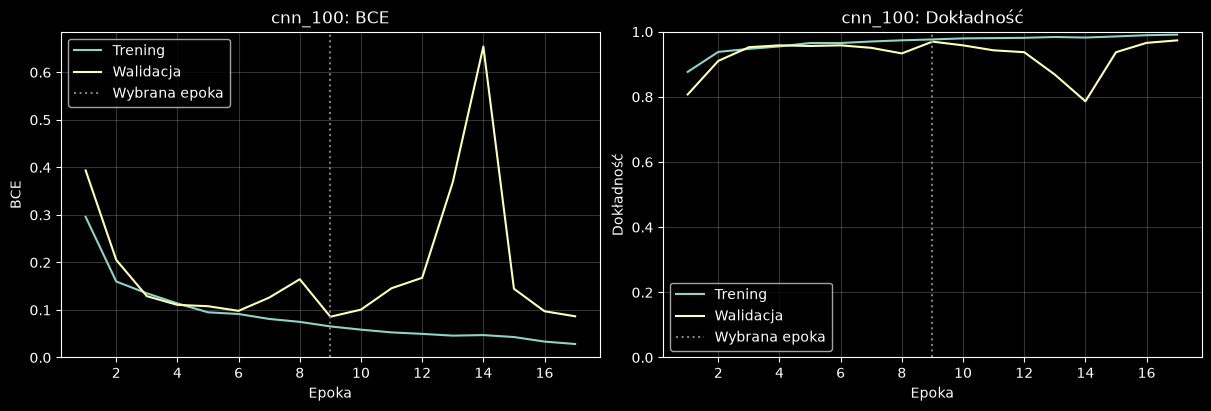

Walidacja: cnn_100
  Dokładność: 0.969
  Czułość: 0.995
  Precyzja: 0.965
  F1: 0.98


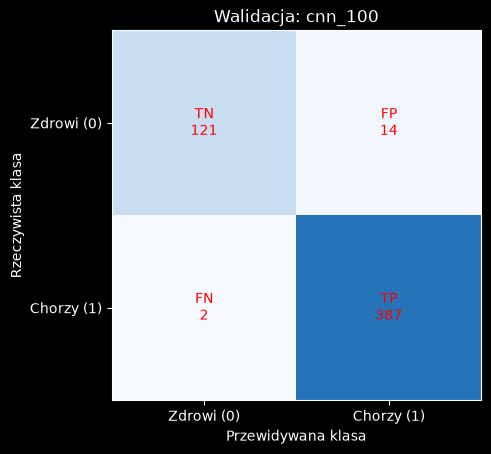

{'TP': 387, 'TN': 121, 'FP': 14, 'FN': 2, 'accuracy': 0.9694656488549618, 'recall': 0.9948586118251928, 'precision': 0.9650872817955112, 'f1': 0.979746835443038, 'run': 'cnn_100', 'percent': 100, 'all_params': 287905, 'trainable_params': 287009, 'train_time_s': 409.0425264170044, 'inference_ms': 0.9825597175611147, 'best_epoch': 9}


In [55]:
cnn.save(output_dir / "model.keras")
best_epoch = plot_history(history, output_dir, RUN_NAME)

val_pred = (cnn.predict(X_val, verbose=0) >= 0.5).astype(int).ravel()
val_metrics = classification_metrics_binary(y_val, val_pred)
show_scores(f"Walidacja: {RUN_NAME}", val_metrics)
plot_confusion_matrix(val_metrics, f"Walidacja: {RUN_NAME}")

results = dict(val_metrics)
results["run"] = RUN_NAME
results["percent"] = PERCENT
results["all_params"] = cnn.count_params()
results["trainable_params"] = count_trainable(cnn)
results["train_time_s"] = train_time
results["inference_ms"] = inference_time_ms(cnn, X_val)
results["best_epoch"] = best_epoch
with open(output_dir / "wyniki.json", "w") as file:
    json.dump(results, file, indent=2)
print(results)

In [56]:
def evaluate_and_save(model, history, train_time, X_eval):
    model.save(output_dir / "model.keras")
    best_epoch = plot_history(history, output_dir, RUN_NAME)

    val_pred = (model.predict(X_eval, verbose=0) >= 0.5).astype(int).ravel()
    val_metrics = classification_metrics_binary(y_val, val_pred)
    show_scores(f"Walidacja: {RUN_NAME}", val_metrics)
    plot_confusion_matrix(val_metrics, f"Walidacja: {RUN_NAME}")

    results = dict(val_metrics)
    results["run"] = RUN_NAME
    results["percent"] = PERCENT
    results["all_params"] = model.count_params()
    results["trainable_params"] = count_trainable(model)
    results["train_time_s"] = train_time
    results["inference_ms"] = inference_time_ms(model, X_eval)
    results["best_epoch"] = best_epoch
    with open(output_dir / "wyniki.json", "w") as file:
        json.dump(results, file, indent=2)
    print(results)

In [79]:
PERCENT = 100
RUN_NAME = f"cechy_{PERCENT}"
output_dir = results_dir / RUN_NAME
output_dir.mkdir(parents=True, exist_ok=True)
X_train, y_train = train_sets[PERCENT]

X_train_rgb = np.repeat(X_train, 3, axis=-1)
X_val_rgb = np.repeat(X_val, 3, axis=-1)

keras.backend.clear_session()
keras.utils.set_random_seed(SEED)

mobile_base = keras.applications.MobileNetV2(
    weights="imagenet", include_top=False,
    input_shape=(96, 96, 3), pooling="avg",
)
mobile_base.trainable = False
print("Parametry bazy:", mobile_base.count_params())

extractor = keras.Sequential([
    keras.layers.Input(shape=(64, 64, 3)),
    keras.layers.Resizing(96, 96),
    keras.layers.Rescaling(1 / 127.5, offset=-1),
    mobile_base,
])
print("Wektor cech:", extractor.output_shape)

Parametry bazy: 2257984
Wektor cech: (None, 1280)


In [80]:
head = keras.Sequential([
    keras.layers.Input(shape=(1280,)),
    keras.layers.Dense(1, activation="sigmoid"),
])
print("Parametry głowicy:", head.count_params())

head.compile(
    optimizer=keras.optimizers.AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss=keras.losses.BinaryCrossentropy(),
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.Recall(name="recall"),
    ],
)

start = time.perf_counter()
H_train = extractor.predict(X_train_rgb, batch_size=64, verbose=0)
H_val = extractor.predict(X_val_rgb, batch_size=64, verbose=0)
history = head.fit(
    H_train, y_train,
    validation_data=(H_val, y_val),
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    callbacks=make_callbacks(output_dir),
    verbose=2,
)
train_time = time.perf_counter() - start
print("Czas treningu [s]:", round(train_time, 1))

Parametry głowicy: 1281
Epoch 1/50
37/37 - 0s - 9ms/step - accuracy: 0.8581 - loss: 0.3315 - recall: 0.9439 - val_accuracy: 0.9237 - val_loss: 0.2047 - val_recall: 0.9820 - learning_rate: 0.0010
Epoch 2/50
37/37 - 0s - 962us/step - accuracy: 0.9282 - loss: 0.1772 - recall: 0.9579 - val_accuracy: 0.9351 - val_loss: 0.1698 - val_recall: 0.9717 - learning_rate: 0.0010
Epoch 3/50
37/37 - 0s - 1ms/step - accuracy: 0.9414 - loss: 0.1493 - recall: 0.9614 - val_accuracy: 0.9389 - val_loss: 0.1559 - val_recall: 0.9743 - learning_rate: 0.0010
Epoch 4/50
37/37 - 0s - 1ms/step - accuracy: 0.9484 - loss: 0.1345 - recall: 0.9657 - val_accuracy: 0.9389 - val_loss: 0.1465 - val_recall: 0.9743 - learning_rate: 0.0010
Epoch 5/50
37/37 - 0s - 956us/step - accuracy: 0.9511 - loss: 0.1243 - recall: 0.9662 - val_accuracy: 0.9427 - val_loss: 0.1394 - val_recall: 0.9769 - learning_rate: 0.0010
Epoch 6/50
37/37 - 0s - 992us/step - accuracy: 0.9537 - loss: 0.1167 - recall: 0.9674 - val_accuracy: 0.9427 - val_lo

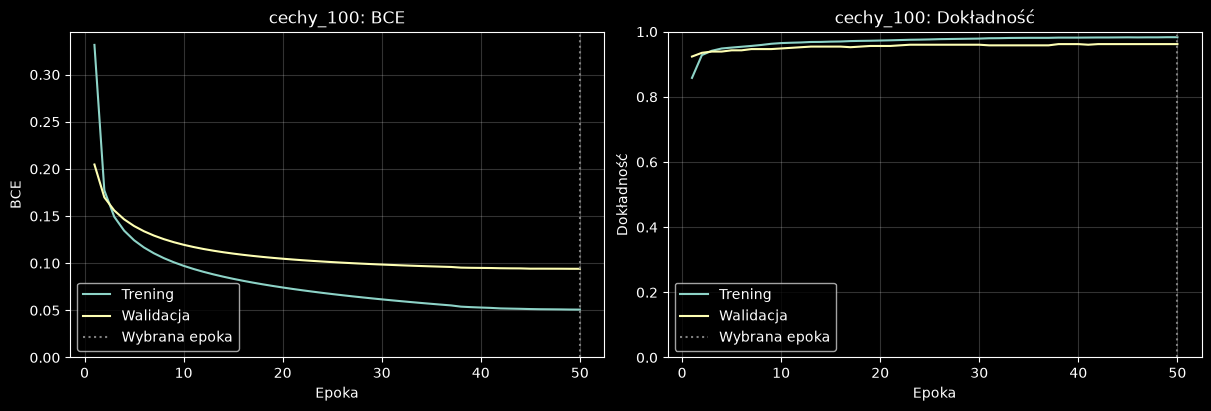

Walidacja: cechy_100
  Dokładność: 0.962
  Czułość: 0.974
  Precyzja: 0.974
  F1: 0.974


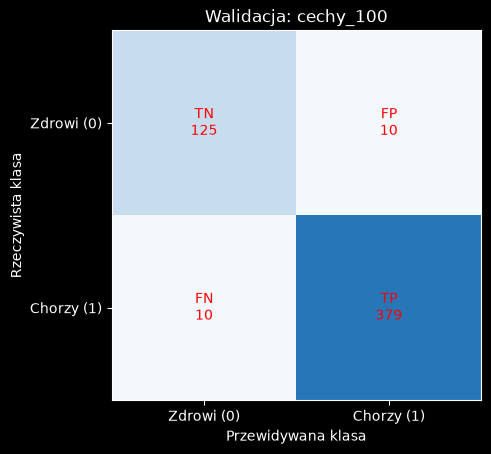

{'TP': 379, 'TN': 125, 'FP': 10, 'FN': 10, 'accuracy': 0.9618320610687023, 'recall': 0.974293059125964, 'precision': 0.974293059125964, 'f1': 0.974293059125964, 'run': 'cechy_100', 'percent': 100, 'all_params': 2259265, 'trainable_params': 1281, 'train_time_s': 7.185050625004806, 'inference_ms': 0.9544906164078488, 'best_epoch': 50}


In [81]:
model = keras.Sequential([extractor, head])
evaluate_and_save(model, history, train_time, X_val_rgb)

In [76]:
head_time = train_time
RUN_NAME = f"dostrajanie_{PERCENT}"
output_dir = results_dir / RUN_NAME
output_dir.mkdir(parents=True, exist_ok=True)

mobile_base.trainable = True
for layer in mobile_base.layers[:-20]:
    layer.trainable = False
for layer in mobile_base.layers:
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=keras.optimizers.AdamW(learning_rate=0.00001, weight_decay=0.0001),
    loss=keras.losses.BinaryCrossentropy(),
    metrics=[keras.metrics.BinaryAccuracy(name="accuracy"), keras.metrics.Recall(name="recall")],
)
print("Wszystkie parametry:", model.count_params())
print("Trenowane parametry:", count_trainable(model))

Wszystkie parametry: 2259265
Trenowane parametry: 1042561


In [77]:
start = time.perf_counter()
history = model.fit(
    X_train_rgb,
    y_train,
    validation_data=(X_val_rgb, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=make_callbacks(output_dir),
    verbose=2,
)
ft_time = time.perf_counter() - start
print("Czas dostrajania [s]:", round(ft_time, 1))
print("Czas łącznie [s]:", round(head_time + ft_time, 1))

Epoch 1/50
12/12 - 4s - 318ms/step - accuracy: 0.9795 - loss: 0.0601 - recall: 0.9857 - val_accuracy: 0.9580 - val_loss: 0.1145 - val_recall: 0.9640 - learning_rate: 1.0000e-05
Epoch 2/50
12/12 - 2s - 145ms/step - accuracy: 0.9837 - loss: 0.0506 - recall: 0.9905 - val_accuracy: 0.9523 - val_loss: 0.1371 - val_recall: 0.9486 - learning_rate: 1.0000e-05
Epoch 3/50
12/12 - 2s - 153ms/step - accuracy: 0.9809 - loss: 0.0547 - recall: 0.9857 - val_accuracy: 0.9580 - val_loss: 0.1255 - val_recall: 0.9563 - learning_rate: 1.0000e-05
Epoch 4/50
12/12 - 2s - 145ms/step - accuracy: 0.9830 - loss: 0.0501 - recall: 0.9866 - val_accuracy: 0.9561 - val_loss: 0.1115 - val_recall: 0.9717 - learning_rate: 1.0000e-05
Epoch 5/50
12/12 - 2s - 148ms/step - accuracy: 0.9887 - loss: 0.0375 - recall: 0.9905 - val_accuracy: 0.9561 - val_loss: 0.1088 - val_recall: 0.9717 - learning_rate: 1.0000e-05
Epoch 6/50
12/12 - 2s - 148ms/step - accuracy: 0.9915 - loss: 0.0327 - recall: 0.9933 - val_accuracy: 0.9523 - val_

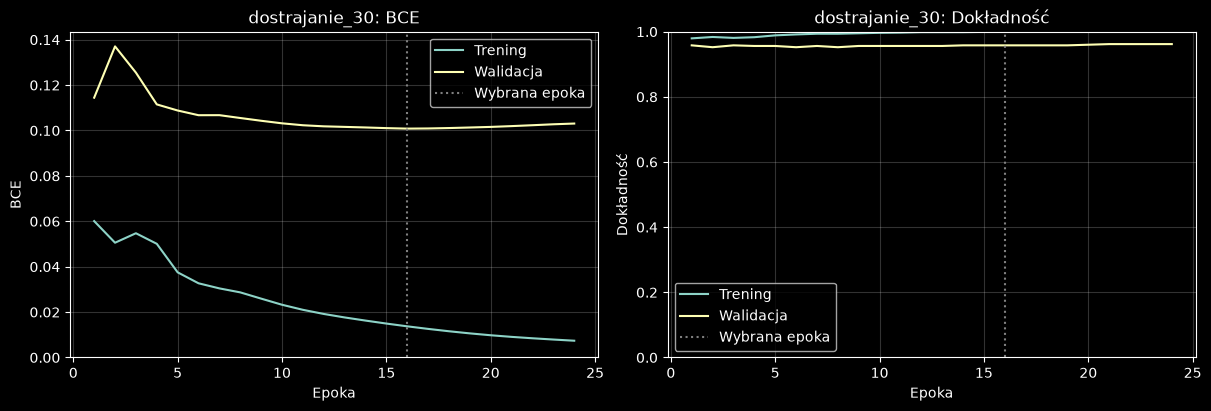

Walidacja: dostrajanie_30
  Dokładność: 0.958
  Czułość: 0.972
  Precyzja: 0.972
  F1: 0.972


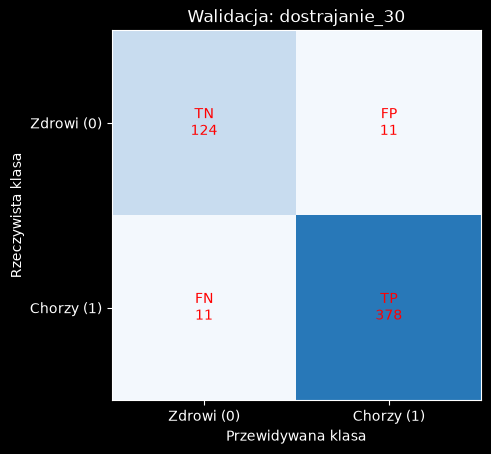

{'TP': 378, 'TN': 124, 'FP': 11, 'FN': 11, 'accuracy': 0.9580152671755725, 'recall': 0.9717223650385605, 'precision': 0.9717223650385605, 'f1': 0.9717223650385605, 'run': 'dostrajanie_30', 'percent': 30, 'all_params': 2259265, 'trainable_params': 1042561, 'train_time_s': 51.2689230420001, 'inference_ms': 0.8396373263347844, 'best_epoch': 16}


In [78]:
evaluate_and_save(model, history, head_time + ft_time, X_val_rgb)

In [46]:
RUN_NAMES = [f"{variant}_{percent}" for variant in ["cnn", "cechy", "dostrajanie"] for percent in [10, 30, 100]]

summary = {}
for name in RUN_NAMES:
    with open(results_dir / name / "wyniki.json") as file:
        results = json.load(file)
    run_model = keras.models.load_model(results_dir / name / "model.keras")
    X_eval = X_val if name.startswith("cnn") else np.repeat(X_val, 3, axis=-1)
    results["inference_ms"] = min(inference_time_ms(run_model, X_eval) for _ in range(3))
    summary[name] = results

b = val_baseline_metrics
print(f"{'Przebieg':<17}{'Dokł.':>7}{'Czuł.':>7}{'Prec.':>7}{'F1':>7}{'FN':>5}{'FP':>5}{'Trenowane':>11}{'Trening [s]':>13}{'Wniosk. [ms]':>14}")
print(f"{'bazowy':<17}{b['accuracy']:>7.3f}{b['recall']:>7.3f}{b['precision']:>7.3f}{b['f1']:>7.3f}{b['FN']:>5}{b['FP']:>5}")
for name in RUN_NAMES:
    r = summary[name]
    print(f"{name:<17}{r['accuracy']:>7.3f}{r['recall']:>7.3f}{r['precision']:>7.3f}{r['f1']:>7.3f}{r['FN']:>5}{r['FP']:>5}"
          f"{r['trainable_params']:>11}{r['train_time_s']:>13.1f}{r['inference_ms']:>14.2f}")

Przebieg           Dokł.  Czuł.  Prec.     F1   FN   FP  Trenowane  Trening [s]  Wniosk. [ms]
bazowy             0.742  1.000  0.742  0.852    0  135
cnn_10             0.897  0.987  0.887  0.934    5   49     287009        103.9          0.90
cnn_30             0.941  0.992  0.932  0.961    3   28     287009        190.0          0.87
cnn_100            0.969  0.995  0.965  0.980    2   14     287009        426.8          0.88
cechy_10           0.931  0.949  0.958  0.953   20   16       1281          3.4          0.78
cechy_30           0.954  0.969  0.969  0.969   12   12       1281          6.9          0.77
cechy_100          0.962  0.974  0.974  0.974   10   10       1281          9.4          0.78
dostrajanie_10     0.933  0.949  0.961  0.955   20   15    1042561         14.0          0.81
dostrajanie_30     0.958  0.972  0.972  0.972   11   11    1042561         54.6          0.88
dostrajanie_100    0.958  0.969  0.974  0.972   12   10    1042561         93.7          0.78


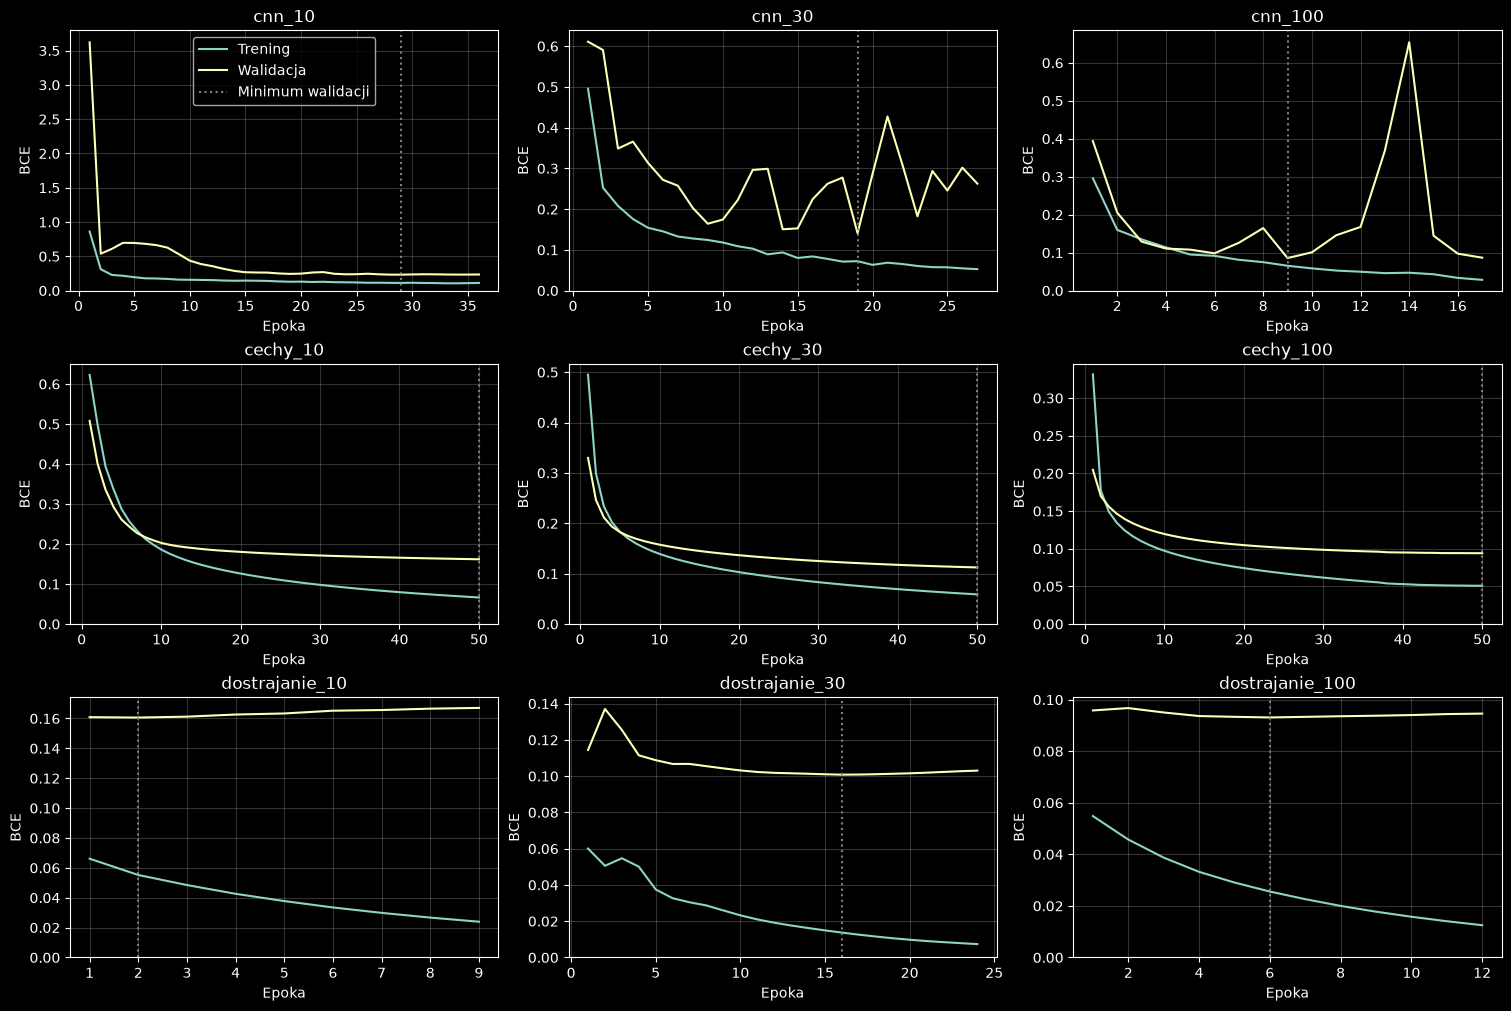

In [47]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10), layout="constrained")
for ax, name in zip(axes.ravel(), RUN_NAMES):
    log = np.genfromtxt(results_dir / name / "historia.csv", delimiter=",", names=True)
    epochs = log["epoch"] + 1
    best_epoch = int(np.argmin(log["val_loss"]) + 1)
    ax.plot(epochs, log["loss"], label="Trening")
    ax.plot(epochs, log["val_loss"], label="Walidacja")
    ax.axvline(best_epoch, color="gray", linestyle=":", label="Minimum walidacji")
    ax.set(xlabel="Epoka", ylabel="BCE", title=name)
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.2)
axes[0, 0].legend()
fig.savefig(results_dir / "porownanie_bce.png", dpi=150, bbox_inches="tight")
plt.show()

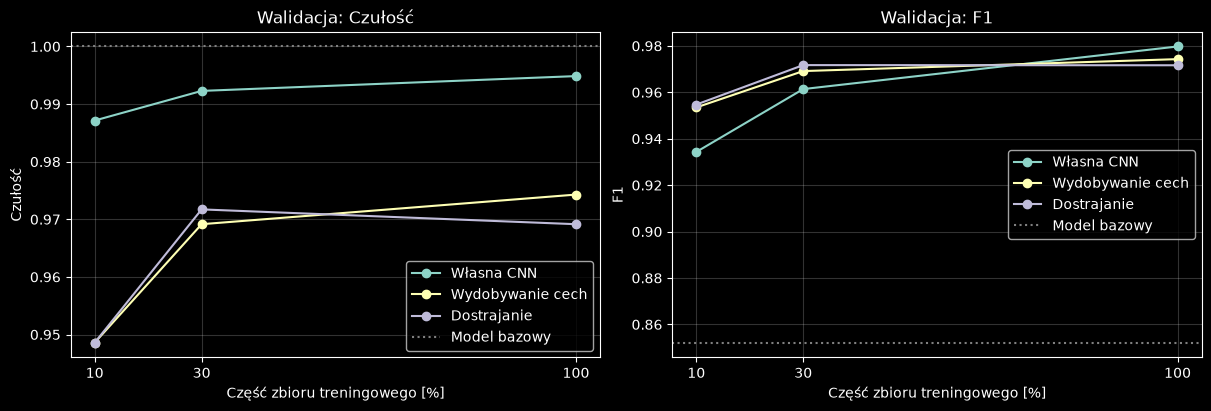

In [48]:
percents = [10, 30, 100]
variants = ["cnn", "cechy", "dostrajanie"]
variant_labels = ["Własna CNN", "Wydobywanie cech", "Dostrajanie"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for ax, key, label in zip(axes, ["recall", "f1"], ["Czułość", "F1"]):
    for variant, variant_label in zip(variants, variant_labels):
        values = [summary[f"{variant}_{percent}"][key] for percent in percents]
        ax.plot(percents, values, marker="o", label=variant_label)
    ax.axhline(val_baseline_metrics[key], color="gray", linestyle=":", label="Model bazowy")
    ax.set(xlabel="Część zbioru treningowego [%]", ylabel=label, title=f"Walidacja: {label}")
    ax.set_xticks(percents)
    ax.grid(alpha=0.2)
    ax.legend()
fig.savefig(results_dir / "jakosc_vs_wielkosc_zbioru.png", dpi=150, bbox_inches="tight")
plt.show()

Test: model bazowy (zawsze zapalenie)
  Dokładność: 0.625
  Czułość: 1.0
  Precyzja: 0.625
  F1: 0.769
Test: cnn_100
  Dokładność: 0.837
  Czułość: 1.0
  Precyzja: 0.793
  F1: 0.884


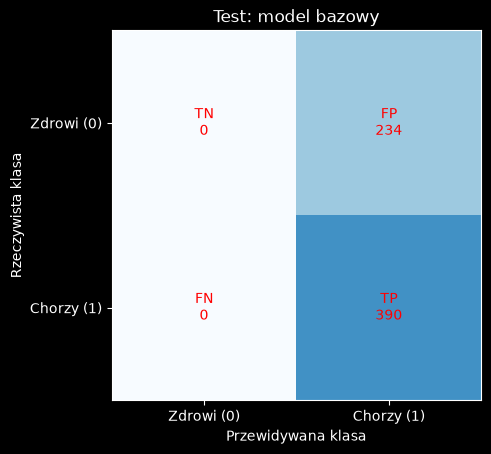

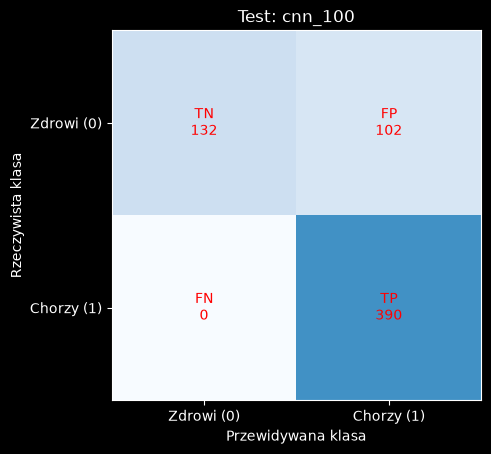

In [49]:
final_name = "cnn_100"
final_model = keras.models.load_model(results_dir / final_name / "model.keras")
test_pred = (final_model.predict(X_test, verbose=0) >= 0.5).astype(int).ravel()
test_metrics = classification_metrics_binary(y_test, test_pred)

test_baseline_pred = np.full(len(y_test), majority_class)
test_baseline_metrics = classification_metrics_binary(y_test, test_baseline_pred)

show_scores("Test: model bazowy (zawsze zapalenie)", test_baseline_metrics)
show_scores(f"Test: {final_name}", test_metrics)
plot_confusion_matrix(test_baseline_metrics, "Test: model bazowy")
plot_confusion_matrix(test_metrics, f"Test: {final_name}")